In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Crop_recommendation.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.shape

(2200, 8)

In [5]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
print("Column names:")
print(df.columns.tolist())

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [8]:
print(df.isnull().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Number of unique crops:", df["label"].nunique())
print("\nCrop counts:")
print(df["label"].value_counts())

Number of unique crops: 22

Crop counts:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [11]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


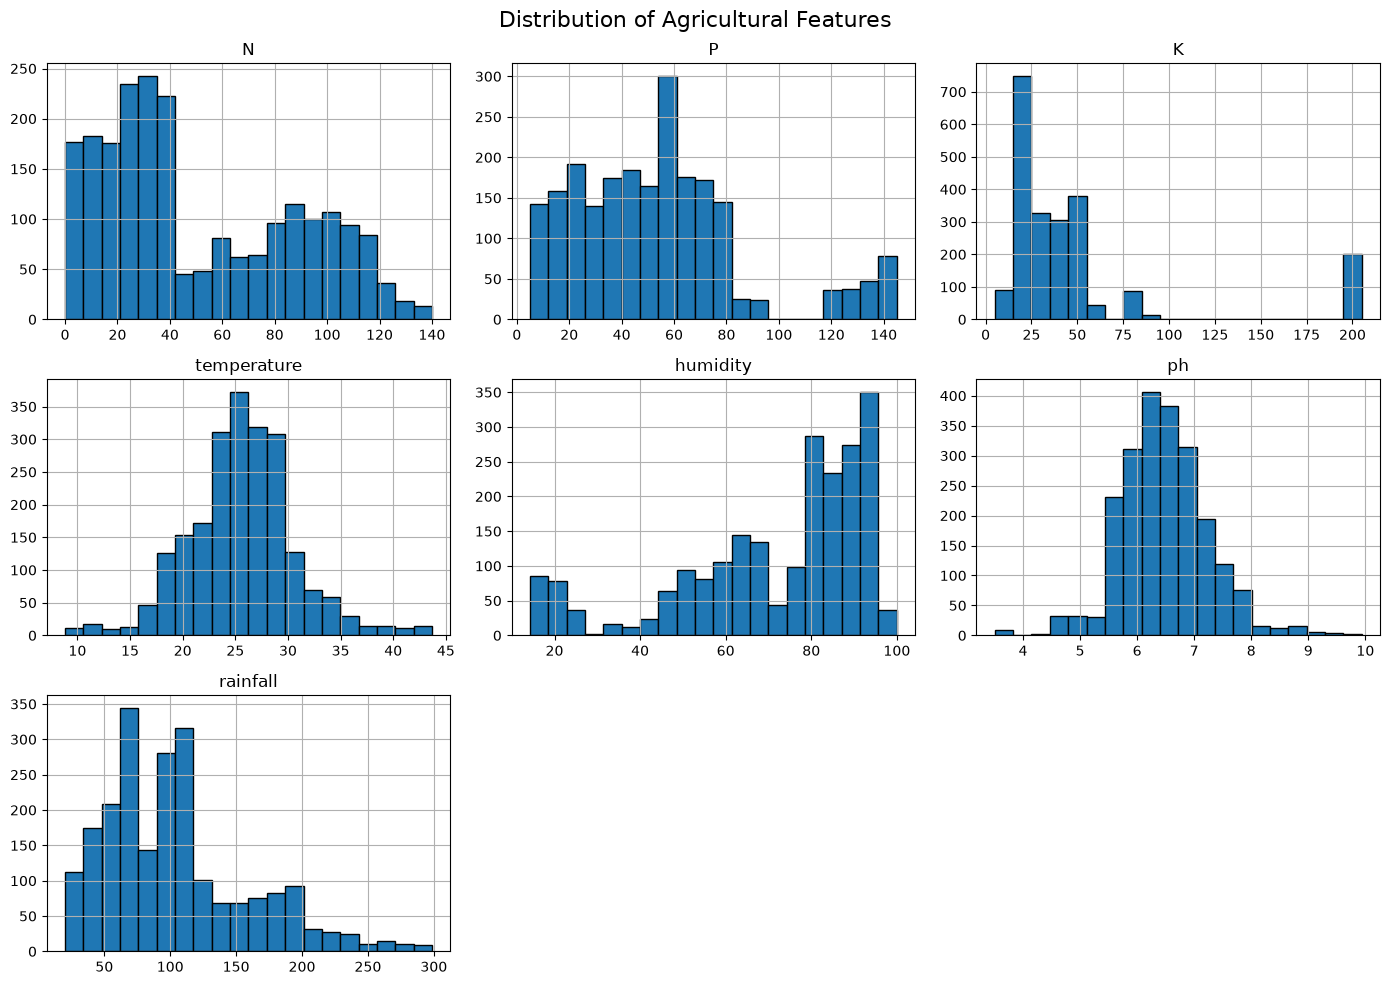

In [12]:
features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

df[features].hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("Distribution of Agricultural Features", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
X = df[features]
y = df["label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2200, 7)
Target shape: (2200,)


In [14]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
dtype: int64

Missing values in y:
0


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1760, 7)
Testing features: (440, 7)
Training labels: (1760,)
Testing labels: (440,)


In [16]:
from sklearn.feature_selection import mutual_info_classif

scores = mutual_info_classif(X_train,y_train,random_state=42)

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "MI_Score": scores
})

feature_scores = feature_scores.sort_values(
    by="MI_Score",
    ascending=False
).reset_index(drop=True)

display(feature_scores)

,Feature,MI_Score
0,humidity,1.732005
1,rainfall,1.632815
2,K,1.631452
3,P,1.296750
4,N,1.014665
5,temperature,0.995991
6,ph,0.709290


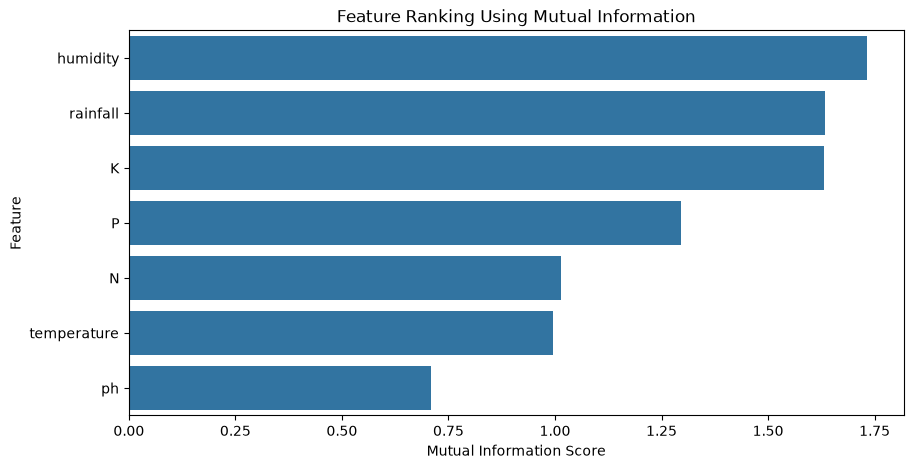

In [17]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_scores,
    x="MI_Score",
    y="Feature"
)

plt.title("Feature Ranking Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.show()

In [18]:
from sklearn.feature_selection import SelectKBest

selected_features = {}

for k in [7]:
    selector = SelectKBest(
        score_func=mutual_info_classif,
        k=k
    )

    selector.fit(X_train, y_train)

    selected = X_train.columns[selector.get_support()].tolist()

    selected_features[k] = selected
    print(selected)

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("Selected Features:", features)
print("Accuracy:", round(accuracy, 4))
print("Macro Precision:", round(precision, 4))
print("Macro Recall:", round(recall, 4))
print("Macro F1 Score:", round(f1, 4))


Selected Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Accuracy: 0.9955
Macro Precision: 0.9957
Macro Recall: 0.9955
Macro F1 Score: 0.9955


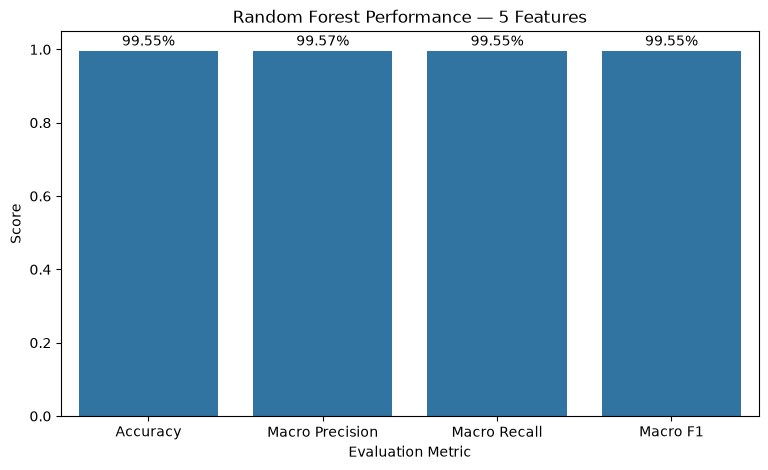

In [20]:
metrics = {
    "Accuracy": accuracy,
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": f1
}

plt.figure(figsize=(9, 5))

sns.barplot(
    x=list(metrics.keys()),
    y=list(metrics.values())
)

plt.title("Random Forest Performance — 5 Features")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)

for i, score in enumerate(metrics.values()):
    plt.text(i, score + 0.015, f"{score:.2%}", ha="center")

plt.show()

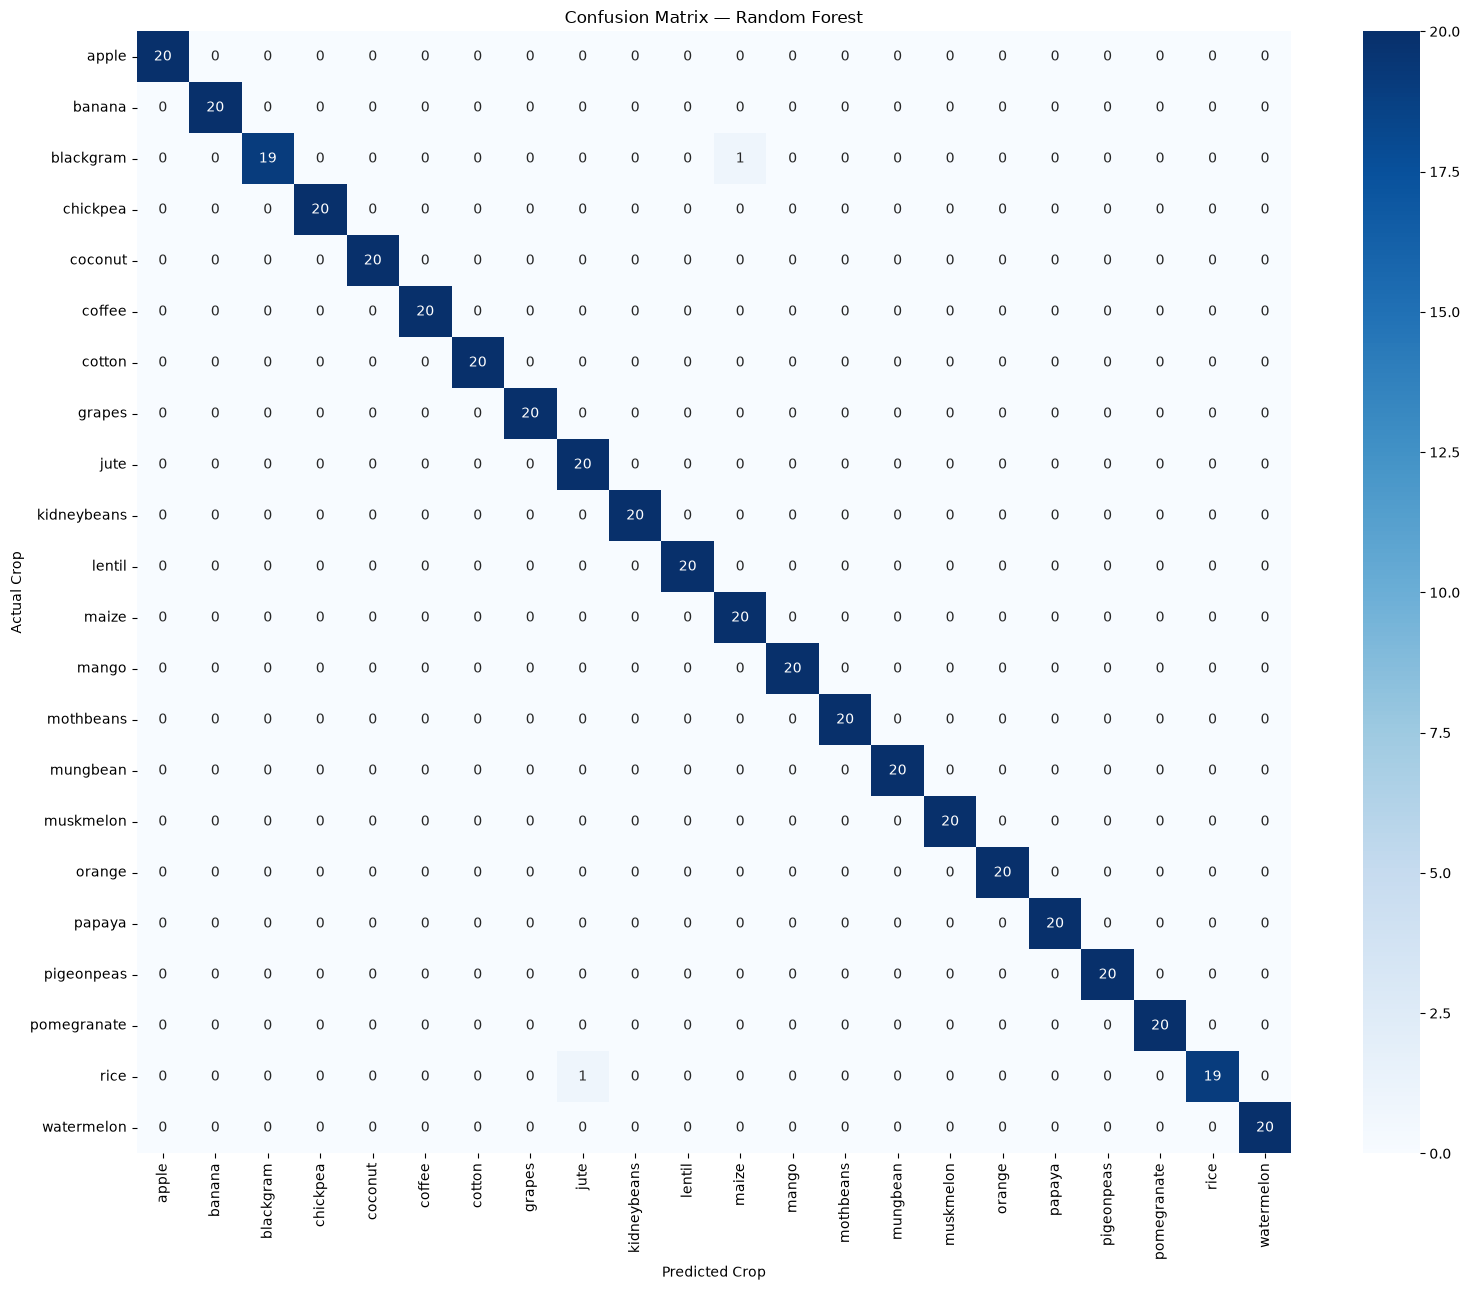

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix — Random Forest")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred,zero_division=0))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [23]:
import os
import joblib

# Select the 5 features used during training
selected = ["N", "P", "K", "temperature","humidity", "ph", "rainfall",]

# Create the models folder in the project root
os.makedirs("../models", exist_ok=True)

# Save the trained model and its feature names
model_data = {
    "model": model,
    "features": selected
}

joblib.dump(model_data, "../models/crop_recommendation_model.pkl")

print("Model saved successfully!")
print("File: models/crop_recommendation_model.pkl")
print("Features:", selected)

Model saved successfully!
File: models/crop_recommendation_model.pkl
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [24]:
import joblib

saved_data = joblib.load(
    "../models/crop_recommendation_model.pkl"
)

loaded_model = saved_data["model"]
loaded_features = saved_data["features"]

print("Model loaded successfully!")
print("Features:", loaded_features)

Model loaded successfully!
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [25]:
import pandas as pd

sample = pd.DataFrame([{
    "N": 90,
    "P": 40,
    "K": 20,
    "temperature": 35,
    "humidity": 80.0,
    "ph": 45.6,
    "rainfall": 200.0

}])

sample = sample[loaded_features]

predicted_crop = loaded_model.predict(sample)[0]

print("Recommended crop:", predicted_crop)

Recommended crop: coffee
